## Load Dataset

In [18]:
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split

About import torchvision.transforms as transforms:


Transforms are common image transformations.\
Converts images into format which can be processes by neural networks (tensors)\
Applies random modification e.g crop, flip rotate and color jitterinng (iiregularites or shaking)\
 Allows you to combine multiple steps together sequentially using transforms.Compose

In [ ]:
# Define transforms to convert to tensors and normalize 

transform = transforms.Compose([
    transforms.ToTensor(), #converts image to tensor (all pixel values 0 to 1 from 0 to 255) and scales pixels
    transforms.Normalize((0.1307,), (0.3081,))  # standardizes the tensor using the given mean and standard deviation
])

In [17]:
full_dataset = datasets.MNIST(
    root='./data', 
    train=True, 
    download=True, 
    transform=transform  # defining the transform we want to apply on our dataset
)

In [19]:
generator = torch.Generator().manual_seed(42)

train_dataset, test_dataset = random_split(full_dataset, [50000, 10000], generator=generator)

In [20]:
train_loader = DataLoader(
    dataset=train_dataset, 
    batch_size=64, 
    shuffle=True
)

In [21]:
test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=1024,
    shuffle=False
)

In [25]:
test_loader

In [ ]:
print(f"Training samples: {len(train_dataset)}")  
print(f"Testing samples: {len(test_dataset)}")    

Training samples: 50000
Testing samples: 10000


In [26]:
images, labels = next(iter(train_loader))

print("--- NN INPUT BATCH METADATA ---")
print(f"Images Tensor Shape : {images.shape}")   # Outputs: torch.Size([64, 1, 28, 28])
print(f"Labels Tensor Shape : {labels.shape}")   # Outputs: torch.Size([64])
print(f"Data Type            : {images.dtype}")   # Outputs: torch.float32
print(f"Value Range (Min/Max): {images.min().item():.4f} to {images.max().item():.4f}")


--- NN INPUT BATCH METADATA ---
Images Tensor Shape : torch.Size([64, 1, 28, 28])
Labels Tensor Shape : torch.Size([64])
Data Type            : torch.float32
Value Range (Min/Max): -0.4242 to 2.8215


In [ ]:
# 1. Fetch the first batch from your DataLoader
images, labels = next(iter(train_loader))

# 2. Extract the very first image's tensor 
first_image_tensor = images[0, 0] # Shape changes from [64, 1, 28, 28] to [28, 28] by selecting the 0th batch and 0th channel
#Take the first image in the batch and its first (and only) channel.

# 3. Configure PyTorch to print the entire matrix without truncating rows or columns
torch.set_printoptions(profile="full", linewidth=200, precision=4)

print(f"--- COMPLETE TENSOR FOR THE FIRST IMAGE (Label: {labels[0].item()}) ---")
print(first_image_tensor)

# Reset print options back to default so your console doesn't get flooded later
torch.set_printoptions(profile="default")

--- COMPLETE TENSOR FOR THE FIRST IMAGE (Label: 7) ---
tensor([[-0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
         -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242],
        [-0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
         -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242],
        [-0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242,
         -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242],
        [-0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.4242, -0.424

In [31]:
import torch
import torch.nn as nn
import torch.optim as optim

class MNIST_NN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
model = MNIST_NN()

# Print architecture
print(model)

# Count trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total trainable parameters: {total_params:,}")

MNIST_NN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Total trainable parameters: 109,386


In [33]:
import torch
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 15

for epoch in range(num_epochs):

    # Training
    model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    train_loss = running_train_loss / len(train_loader.dataset)


    # Validation
    model.eval()
    running_test_loss = 0.0

    with torch.no_grad():

        for images, labels in test_loader:

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_test_loss += loss.item() * images.size(0)

    test_loss = running_test_loss / len(test_loader.dataset)


    print(
        f"Epoch [{epoch+1:2d}/{num_epochs}] "
        f"Training Loss: {train_loss:.4f} "
        f"Validation Loss: {test_loss:.4f}"
    )

Epoch [ 1/15] Training Loss: 0.1222 Validation Loss: 0.1248
Epoch [ 2/15] Training Loss: 0.0814 Validation Loss: 0.1028
Epoch [ 3/15] Training Loss: 0.0610 Validation Loss: 0.0985
Epoch [ 4/15] Training Loss: 0.0484 Validation Loss: 0.0919
Epoch [ 5/15] Training Loss: 0.0377 Validation Loss: 0.1005
Epoch [ 6/15] Training Loss: 0.0331 Validation Loss: 0.1157
Epoch [ 7/15] Training Loss: 0.0276 Validation Loss: 0.1054
Epoch [ 8/15] Training Loss: 0.0255 Validation Loss: 0.1159
Epoch [ 9/15] Training Loss: 0.0208 Validation Loss: 0.1051
Epoch [10/15] Training Loss: 0.0198 Validation Loss: 0.1167
Epoch [11/15] Training Loss: 0.0183 Validation Loss: 0.1200
Epoch [12/15] Training Loss: 0.0173 Validation Loss: 0.1282
Epoch [13/15] Training Loss: 0.0146 Validation Loss: 0.1231
Epoch [14/15] Training Loss: 0.0126 Validation Loss: 0.1326
Epoch [15/15] Training Loss: 0.0168 Validation Loss: 0.1372


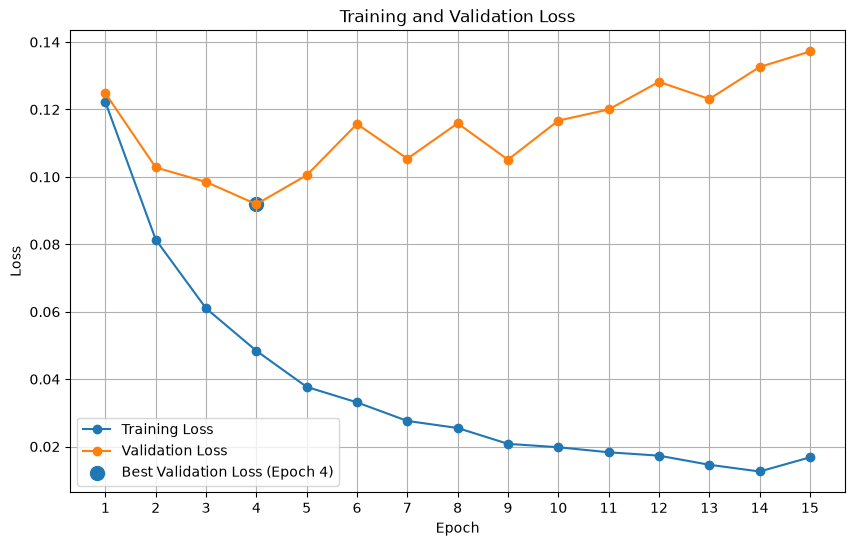

Lowest validation loss: 0.0919
Best epoch: 4

Overfitting: YES
Training loss continues to decrease while validation loss generally increases after epoch 4.


In [34]:
import matplotlib.pyplot as plt

epochs = range(1, 16)

train_losses = [
    0.1222, 0.0814, 0.0610, 0.0484, 0.0377,
    0.0331, 0.0276, 0.0255, 0.0208, 0.0198,
    0.0183, 0.0173, 0.0146, 0.0126, 0.0168
]

val_losses = [
    0.1248, 0.1028, 0.0985, 0.0919, 0.1005,
    0.1157, 0.1054, 0.1159, 0.1051, 0.1167,
    0.1200, 0.1282, 0.1231, 0.1326, 0.1372
]

# Find epoch with lowest validation loss
best_epoch = val_losses.index(min(val_losses)) + 1
best_val_loss = min(val_losses)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(epochs, train_losses, marker='o', label='Training Loss')
plt.plot(epochs, val_losses, marker='o', label='Validation Loss')

# Mark best validation epoch
plt.scatter(
    best_epoch,
    best_val_loss,
    s=100,
    label=f'Best Validation Loss (Epoch {best_epoch})'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()

print(f"Lowest validation loss: {best_val_loss:.4f}")
print(f"Best epoch: {best_epoch}")

print("\nOverfitting: YES")
print("Training loss continues to decrease while validation loss generally increases after epoch 4.")

In [35]:
class MNIST_NN_Dropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model_dropout = MNIST_NN_Dropout()

print(model_dropout)

MNIST_NN_Dropout(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model_dropout.parameters(),
    lr=0.001
)

num_epochs = 15
patience = 3  # Allow the model 3 consecutive epochs without improvement in validation loss before stopping training.

train_losses_dropout = []
val_losses_dropout = []

best_val_loss = float('inf')
best_weights = None

epochs_without_improvement = 0


for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model_dropout.train()

    running_train_loss = 0.0

    for images, labels in train_loader:

        outputs = model_dropout(images)

        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    train_loss = running_train_loss / len(train_loader.dataset)


    # --------------------
    # Validation
    # --------------------
    model_dropout.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for images, labels in test_loader:

            outputs = model_dropout(images)

            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

    val_loss = running_val_loss / len(test_loader.dataset)


    # Store losses
    train_losses_dropout.append(train_loss)
    val_losses_dropout.append(val_loss)


    # --------------------
    # Early stopping
    # --------------------

    if val_loss < best_val_loss:

        # Validation improved
        best_val_loss = val_loss
        best_weights = model_dropout.state_dict()

        epochs_without_improvement = 0

    else:

        # No improvement
        epochs_without_improvement += 1


    print(
        f"Epoch [{epoch+1:2d}/{num_epochs}] "
        f"Training Loss: {train_loss:.4f} "
        f"Validation Loss: {val_loss:.4f}"
    )


    # Stop if validation hasn't improved for 3 epochs
    if epochs_without_improvement >= patience:

        print(f"\nEarly stopping at epoch {epoch+1}")
        break

Epoch [ 1/15] Training Loss: 0.4370 Validation Loss: 0.1972
Epoch [ 2/15] Training Loss: 0.2277 Validation Loss: 0.1451
Epoch [ 3/15] Training Loss: 0.1827 Validation Loss: 0.1234
Epoch [ 4/15] Training Loss: 0.1600 Validation Loss: 0.1175
Epoch [ 5/15] Training Loss: 0.1438 Validation Loss: 0.1197
Epoch [ 6/15] Training Loss: 0.1336 Validation Loss: 0.1162
Epoch [ 7/15] Training Loss: 0.1249 Validation Loss: 0.1077
Epoch [ 8/15] Training Loss: 0.1166 Validation Loss: 0.1016
Epoch [ 9/15] Training Loss: 0.1126 Validation Loss: 0.1097
Epoch [10/15] Training Loss: 0.1075 Validation Loss: 0.1078
Epoch [11/15] Training Loss: 0.1045 Validation Loss: 0.1076

Early stopping at epoch 11


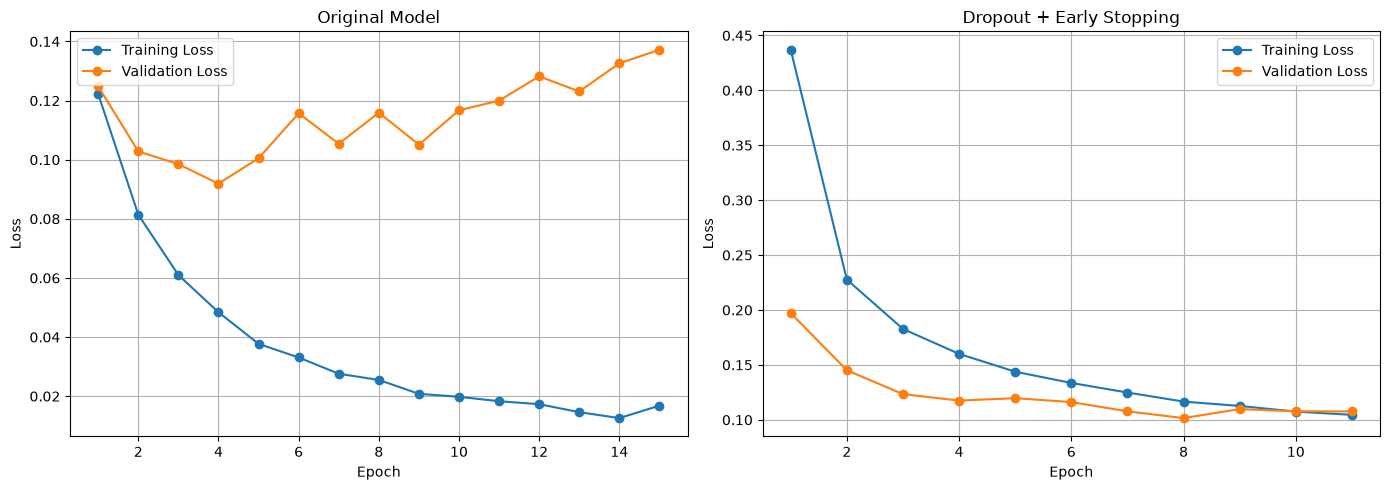

In [43]:
plt.figure(figsize=(14, 5))

# ─────────────────────────────
# Graph 1: Original Model
# ─────────────────────────────
plt.subplot(1, 2, 1)

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Original Model')
plt.legend()
plt.grid(True)


# ─────────────────────────────
# Graph 2: Dropout + Early Stopping
# ─────────────────────────────
plt.subplot(1, 2, 2)

plt.plot(
    range(1, len(train_losses_dropout) + 1),
    train_losses_dropout,
    marker='o',
    label='Training Loss'
)

plt.plot(
    range(1, len(val_losses_dropout) + 1),
    val_losses_dropout,
    marker='o',
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Dropout + Early Stopping')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [44]:
test_dataset = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

official_test_loader = DataLoader(
    test_dataset,
    batch_size=1024,
    shuffle=False
)

model_dropout.load_state_dict(best_weights)

<All keys matched successfully>

In [45]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

model_dropout.eval()

correct = 0
total = 0

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in official_test_loader:

        outputs = model_dropout(images)

        # Predicted digit = class with highest output
        _, predictions = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_accuracy = correct / total

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 0.9773
Test Accuracy: 97.73%


In [46]:
cm = confusion_matrix(all_labels, all_predictions)

print(cm)

[[ 968    1    1    1    0    3    4    1    1    0]
 [   0 1127    3    1    0    2    1    0    1    0]
 [   3    3 1008    0    5    0    1    9    3    0]
 [   0    1    2  991    1    5    0    6    3    1]
 [   0    0    2    0  970    0    5    0    0    5]
 [   2    0    0    9    1  871    3    1    1    4]
 [   5    3    1    1    7    5  932    1    3    0]
 [   1    6    9    0    3    0    0 1006    0    3]
 [   4    3    2    7    5   10    1    7  929    6]
 [   3    3    0    3   19    4    0    6    0  971]]


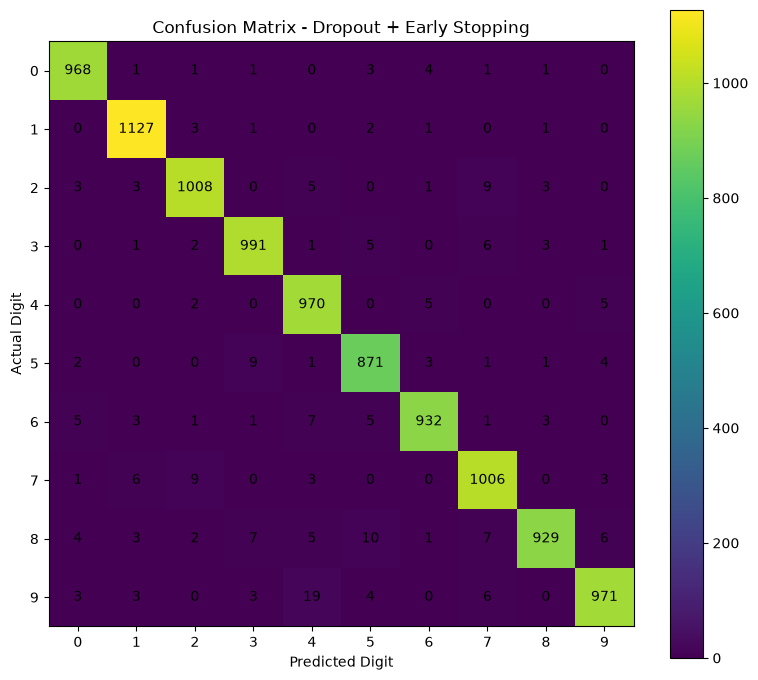

In [47]:
plt.figure(figsize=(8, 7))

plt.imshow(cm, interpolation='nearest')

plt.title('Confusion Matrix - Dropout + Early Stopping')
plt.xlabel('Predicted Digit')
plt.ylabel('Actual Digit')

plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))

# Write the numbers inside each cell
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j],
                 ha='center',
                 va='center')

plt.tight_layout()
plt.show()

The most confused digit is 9 with 4 which is 19 times